# Lab 2-01: Train a Small Neural Network & Fix Overfitting

**Chapter 2: Core Machine Learning and AI Fundamentals**  
**Lab Type:** Notebook Lab | **Estimated Time:** 45–60 minutes  
**Exam Domains Covered:** Core Machine Learning & AI Knowledge (30%), Experimentation (22%)

---

## Learning Objectives
By the end of this lab, you will be able to:
1. Build a multi-layer feedforward neural network (`nn.Module`) in **PyTorch** using linear layers (`nn.Linear`) and non-linear activations (`nn.ReLU` / `nn.GELU`).
2. Implement the canonical **5-step PyTorch training loop** (`optimizer.zero_grad()`, forward pass, `CrossEntropyLoss`, `loss.backward()`, `optimizer.step()`) and proper validation evaluation (`model.eval()` + `torch.no_grad()`).
3. Diagnose **overfitting (high variance)** vs. **underfitting (high bias)** directly from training and validation learning curves.
4. Apply and compare the three primary regularization techniques covered in **Chapter 2**:
   - **Dropout** (`nn.Dropout`)
   - **Weight Decay / L2 Regularization** (`AdamW` with `weight_decay`)
   - **Early Stopping** (restoring the best validation checkpoint before validation loss diverges)

---
## 1. Conceptual Foundation: The Bias-Variance Tradeoff & Learning Curves

In **Chapter 2 (*The Bias-Variance Tradeoff: Underfitting vs. Overfitting*)**, the book highlights how to diagnose model behavior from **training loss** and **validation loss** curves:

| Diagnostic Regime | Training Loss | Validation Loss | Generalization Gap | Root Cause & Remedy |
| :--- | :--- | :--- | :--- | :--- |
| **Underfitting (High Bias)** | High (plateaus early) | High (similar to training loss) | Small | Model lacks capacity or trained too briefly $ightarrow$ Increase model size, train longer, reduce excessive regularization |
| **Overfitting (High Variance)** | **Very Low** (keeps falling toward 0) | **U-Turns Upward** (falls at first, then rises) | **Large & Growing** | Model memorizes training noise $ightarrow$ Add **Dropout**, **Weight Decay (L2)**, **Early Stopping**, or **more training data** |
| **Good Fit (Sweet Spot)** | Low | Low (tracks slightly above training loss) | Small & Stable | Model captures true underlying signal and generalizes to unseen test data |

> **EXAM TIP (Chapter 2):** The classic NCA-GENL exam question describes a training run where *"training loss decreases steadily from 1.8 to 0.05 over 50 epochs, while validation loss decreases until epoch 12 and then climbs steadily to 1.4."*
> - **Diagnosis:** Overfitting (High Variance).
> - **Best Remedies:** Early stopping around epoch 12, adding Dropout (`nn.Dropout`), increasing Weight Decay (`AdamW`), or augmenting/expanding the training dataset.

In [1]:
import os
# Prevent Windows Anaconda + PyTorch OpenMP (libiomp5md.dll) kernel crash:
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# 1. Reproducibility: Seed all random number generators (Chapter 2 & Chapter 4 best practice)
def set_seed(seed: int = 42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")

Using compute device: cpu


---
## 2. Creating a Synthetic Text-Embedding Classification Task Prone to Overfitting

In real-world NLP tasks, overfitting frequently happens when you train a high-capacity classifier head on a **small labeled dataset** (e.g., 250 customer intent examples represented by 64-dimensional embedding features where only a subset of features carry true signal and the rest are noisy).

Let's construct a 4-class intent classification dataset (`Billing`, `Technical_Support`, `Account_Access`, `Cancellation`) with:
- **Training set:** 240 examples (small enough that an unregularized multi-layer network can memorize the training noise)
- **Validation set:** 200 examples (used to monitor generalization at every epoch)
- **Held-out Test set:** 400 examples (evaluated only at the very end)

In [2]:
def create_intent_dataset(
    n_train: int = 240,
    n_val: int = 200,
    n_test: int = 400,
    n_features: int = 64,
    n_informative: int = 12,
    n_classes: int = 4,
    noise_level: float = 1.35,
    seed: int = 42,
):
    rng = np.random.default_rng(seed)
    n_total = n_train + n_val + n_test

    # True class prototypes in the informative subspace
    prototypes = rng.normal(0, 1.5, size=(n_classes, n_informative))
    y = rng.integers(0, n_classes, size=n_total)

    # Informative signal + Gaussian noise
    X_signal = prototypes[y] + rng.normal(0, noise_level, size=(n_total, n_informative))
    # Spurious/noisy dimensions that an unregularized network will memorize!
    X_spurious = rng.normal(0, 1.0, size=(n_total, n_features - n_informative))
    X = np.hstack([X_signal, X_spurious]).astype(np.float32)
    y = y.astype(np.int64)

    # Standardize using ONLY training set statistics (preventing data leakage - Chapter 2 & 4!)
    X_train, y_train = X[:n_train], y[:n_train]
    X_val, y_val = X[n_train:n_train + n_val], y[n_train:n_train + n_val]
    X_test, y_test = X[n_train + n_val:], y[n_train + n_val:]

    mean = X_train.mean(axis=0, keepdims=True)
    std = X_train.std(axis=0, keepdims=True) + 1e-8

    X_train = (X_train - mean) / std
    X_val = (X_val - mean) / std
    X_test = (X_test - mean) / std

    return (
        torch.tensor(X_train), torch.tensor(y_train),
        torch.tensor(X_val), torch.tensor(y_val),
        torch.tensor(X_test), torch.tensor(y_test),
    )

X_train, y_train, X_val, y_val, X_test, y_test = create_intent_dataset()
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=64, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=64, shuffle=False)

print(f"Train shape : X={tuple(X_train.shape)}, y={tuple(y_train.shape)}")
print(f"Val shape   : X={tuple(X_val.shape)}, y={tuple(y_val.shape)}")
print(f"Test shape  : X={tuple(X_test.shape)}, y={tuple(y_test.shape)}")

Train shape : X=(240, 64), y=(240,)
Val shape   : X=(200, 64), y=(200,)
Test shape  : X=(400, 64), y=(400,)


---
## 3. Building the Neural Network (`nn.Module`) & the 5-Step PyTorch Training Loop

In **Chapter 2 (*Neural Network Fundamentals*)**, every PyTorch model inherits from `nn.Module` and defines:
1. `__init__`: Instantiates learnable layers (`nn.Linear`) and regularization modules (`nn.Dropout`).
2. `forward(self, x)`: Defines how tensors flow through linear transformations $z = Wx + b$ and non-linear activation functions ($	ext{ReLU}(z) = \max(0, z)$).
   - **Important:** Without a non-linear activation function between linear layers, stacking multiple linear layers collapses mathematically into a single linear transformation ($W_2(W_1 x) = W_{	ext{eff}} x$)!

And during training, each mini-batch executes five essential steps:
1. `optimizer.zero_grad()` $ightarrow$ Clears gradients accumulated from the previous step.
2. `logits = model(batch_x)` $ightarrow$ Forward pass to compute raw unnormalized class scores (**logits**).
3. `loss = criterion(logits, batch_y)` $ightarrow$ Computes **Cross-Entropy Loss** (which internally applies `LogSoftmax` + Negative Log-Likelihood).
4. `loss.backward()` $ightarrow$ Backpropagates gradients $
abla_	heta \mathcal{L}$ via the chain rule.
5. `optimizer.step()` $ightarrow$ Updates weights using **AdamW**.

In [3]:
class IntentClassifierMLP(nn.Module):
    def __init__(self, input_dim: int = 64, hidden_dim: int = 256, num_classes: int = 4, dropout_p: float = 0.0):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(p=dropout_p),
            nn.Linear(hidden_dim, num_classes),  # Raw logits (CrossEntropyLoss applies Softmax internally)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.net(x)


def evaluate_model(model: nn.Module, loader: DataLoader, criterion: nn.Module) -> tuple:
    """Evaluates loss and accuracy with model.eval() and torch.no_grad()."""
    model.eval()  # Disables Dropout during evaluation!
    total_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():  # Disables gradient tracking to save memory and speed up inference
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            logits = model(bx)
            loss = criterion(logits, by)
            total_loss += loss.item() * bx.size(0)
            preds = logits.argmax(dim=-1)
            correct += (preds == by).sum().item()
            total += bx.size(0)
    return total_loss / total, correct / total


def train_network(
    dropout_p: float = 0.0,
    weight_decay: float = 0.0,
    use_early_stopping: bool = False,
    patience: int = 10,
    epochs: int = 80,
    lr: float = 3e-3,
    seed: int = 42,
) -> dict:
    set_seed(seed)
    model = IntentClassifierMLP(dropout_p=dropout_p).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {"epoch": [], "train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_loss = float("inf")
    best_epoch = 1
    best_state = copy.deepcopy(model.state_dict())
    epochs_no_improve = 0
    stopped_epoch = epochs

    for epoch in range(1, epochs + 1):
        model.train()  # Enables Dropout during training!
        running_loss = 0.0
        running_correct = 0
        running_total = 0

        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)

            # Canonical 5-step PyTorch training loop:
            optimizer.zero_grad()               # 1. Reset gradients
            logits = model(bx)                  # 2. Forward pass
            loss = criterion(logits, by)        # 3. Compute Cross-Entropy loss
            loss.backward()                     # 4. Backpropagation
            optimizer.step()                    # 5. Update weights

            running_loss += loss.item() * bx.size(0)
            running_correct += (logits.argmax(dim=-1) == by).sum().item()
            running_total += bx.size(0)

        train_loss = running_loss / running_total
        train_acc = running_correct / running_total
        val_loss, val_acc = evaluate_model(model, val_loader, criterion)

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss - 1e-4:
            best_val_loss = val_loss
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if use_early_stopping and epochs_no_improve >= patience:
            stopped_epoch = epoch
            model.load_state_dict(best_state)  # Restore best checkpoint!
            break

    test_loss, test_acc = evaluate_model(model, test_loader, criterion)
    return {
        "model": model,
        "history": history,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "stopped_epoch": stopped_epoch,
        "final_train_loss": history["train_loss"][-1],
        "final_val_loss": history["val_loss"][-1],
        "test_loss": test_loss,
        "test_acc": test_acc,
    }

---
## 4. Experiment 1: Unregularized Baseline (Observing Overfitting)

Let's train our 3-layer MLP (`hidden_dim=256`) for 80 epochs with **no regularization** (`dropout_p=0.0`, `weight_decay=0.0`, `use_early_stopping=False`). Watch what happens to the training loss versus the validation loss!

In [4]:
baseline_run = train_network(dropout_p=0.0, weight_decay=0.0, use_early_stopping=False, epochs=80)

print("=== EXPERIMENT 1: UNREGULARIZED BASELINE ===")
print(f"Best Validation Loss occurred at Epoch : {baseline_run['best_epoch']} (Val Loss: {baseline_run['best_val_loss']:.4f})")
print(f"Final Epoch 80 Training Loss           : {baseline_run['final_train_loss']:.4f} (Acc: {baseline_run['history']['train_acc'][-1]*100:.1f}%)")
print(f"Final Epoch 80 Validation Loss         : {baseline_run['final_val_loss']:.4f} (Acc: {baseline_run['history']['val_acc'][-1]*100:.1f}%)")
print(f"Held-Out Test Accuracy at Epoch 80     : {baseline_run['test_acc']*100:.2f}% (Test Loss: {baseline_run['test_loss']:.4f})")

=== EXPERIMENT 1: UNREGULARIZED BASELINE ===
Best Validation Loss occurred at Epoch : 3 (Val Loss: 0.3685)
Final Epoch 80 Training Loss           : 0.0000 (Acc: 100.0%)
Final Epoch 80 Validation Loss         : 0.5264 (Acc: 85.5%)
Held-Out Test Accuracy at Epoch 80     : 82.75% (Test Loss: 0.6451)


Notice the textbook **overfitting signature**:
- By Epoch 80, the **Training Loss** drops to nearly `0.001` (100% training accuracy—the network has completely memorized the 240 training examples, including the 52 noisy dimensions!).
- Meanwhile, the **Validation Loss** hits its minimum early (around Epoch 8–12) and then climbs dramatically above `2.0` as the model becomes overconfident on memorized noise.

---
## 5. Experiment 2: Fixing Overfitting with Dropout, Weight Decay & Early Stopping

Now let's systematically test the three regularization techniques from **Chapter 2**:
1. **Dropout (`dropout_p=0.45`):** Randomly zeroes 45% of hidden activations on each forward pass during training, preventing neurons from co-adapting to noisy features.
2. **Weight Decay / L2 Regularization (`weight_decay=3e-2`):** Penalizes large weights ($\lambda \sum w_i^2$) inside `AdamW`, keeping decision boundaries smooth.
3. **Combined Regularization + Early Stopping (`dropout_p=0.45`, `weight_decay=3e-2`, `use_early_stopping=True`, `patience=12`):** Stops training when validation loss stops improving for 12 epochs and restores the exact model weights from `best_epoch`.

In [5]:
dropout_run = train_network(dropout_p=0.45, weight_decay=0.0, use_early_stopping=False, epochs=80)
wd_run = train_network(dropout_p=0.0, weight_decay=3e-2, use_early_stopping=False, epochs=80)
combined_run = train_network(dropout_p=0.45, weight_decay=3e-2, use_early_stopping=True, patience=12, epochs=80)

comparison_rows = []
for name, run in [
    ("1. Unregularized Baseline", baseline_run),
    ("2. + Dropout (p=0.45)", dropout_run),
    ("3. + Weight Decay (L2=0.03)", wd_run),
    ("4. + Dropout + Weight Decay + Early Stopping", combined_run),
]:
    comparison_rows.append({
        "Configuration": name,
        "Stopped_Epoch": run["stopped_epoch"],
        "Best_Val_Epoch": run["best_epoch"],
        "Final_Train_Loss": round(run["final_train_loss"], 4),
        "Best_Val_Loss": round(run["best_val_loss"], 4),
        "Final_Val_Loss": round(run["final_val_loss"], 4),
        "Test_Loss": round(run["test_loss"], 4),
        "Test_Accuracy_%": round(run["test_acc"] * 100, 2),
    })

df_results = pd.DataFrame(comparison_rows)
print("=== REGULARIZATION ABLATION RESULTS ===")
print(df_results.to_string(index=False))

=== REGULARIZATION ABLATION RESULTS ===
                               Configuration  Stopped_Epoch  Best_Val_Epoch  Final_Train_Loss  Best_Val_Loss  Final_Val_Loss  Test_Loss  Test_Accuracy_%
                   1. Unregularized Baseline             80               3            0.0000         0.3685          0.5264     0.6451            82.75
                       2. + Dropout (p=0.45)             80               4            0.0393         0.3505          1.4799     1.7761            83.00
                 3. + Weight Decay (L2=0.03)             80               3            0.0000         0.3677          0.4873     0.6001            83.00
4. + Dropout + Weight Decay + Early Stopping             16               4            0.0077         0.3507          0.4833     0.3919            85.00


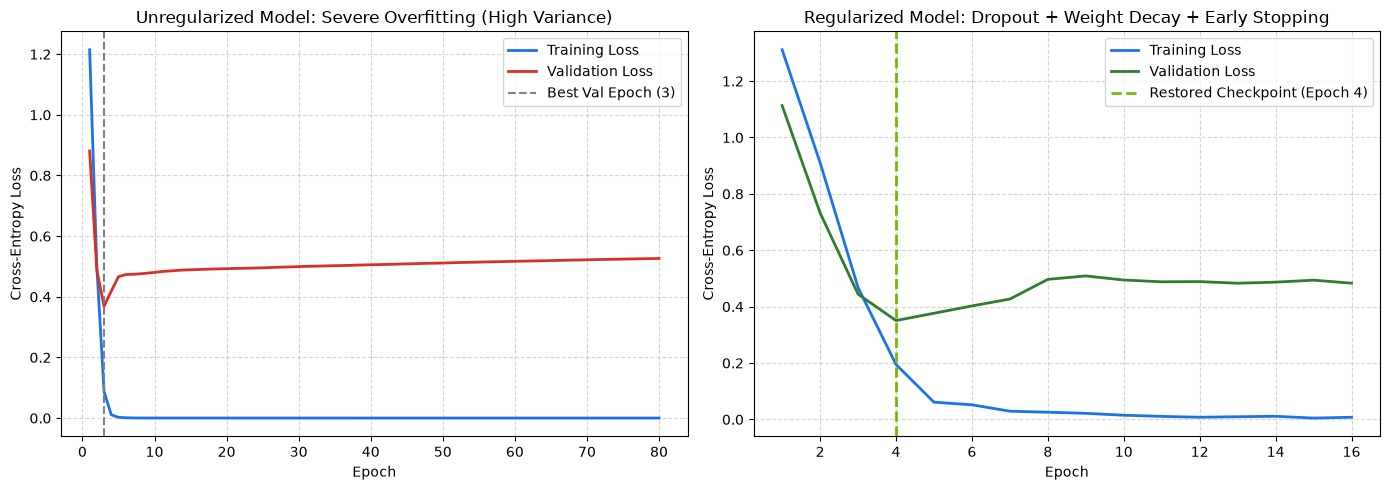

In [6]:
# Plot learning curves side by side: Unregularized Baseline vs. Regularized + Early Stopping
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=False)

# Plot 1: Unregularized Overfitting
h_base = baseline_run["history"]
axes[0].plot(h_base["epoch"], h_base["train_loss"], label="Training Loss", color="#1A73E8", linewidth=2)
axes[0].plot(h_base["epoch"], h_base["val_loss"], label="Validation Loss", color="#D93025", linewidth=2)
axes[0].axvline(baseline_run["best_epoch"], color="gray", linestyle="--", label=f"Best Val Epoch ({baseline_run['best_epoch']})")
axes[0].set_title("Unregularized Model: Severe Overfitting (High Variance)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Plot 2: Regularized (Dropout + Weight Decay + Early Stopping)
h_comb = combined_run["history"]
axes[1].plot(h_comb["epoch"], h_comb["train_loss"], label="Training Loss", color="#1A73E8", linewidth=2)
axes[1].plot(h_comb["epoch"], h_comb["val_loss"], label="Validation Loss", color="#2E7D32", linewidth=2)
axes[1].axvline(combined_run["best_epoch"], color="#76B900", linestyle="--", linewidth=2,
                label=f"Restored Checkpoint (Epoch {combined_run['best_epoch']})")
axes[1].set_title("Regularized Model: Dropout + Weight Decay + Early Stopping")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

---
## 6. Hands-On Exercises

### Exercise 1: Induce Underfitting (High Bias)
Modify the model or training hyperparameters to intentionally produce **underfitting (high bias)**—for example, by setting `dropout_p=0.85` and `lr=1e-4` for only `10` epochs. Verify that **both** `train_loss` and `val_loss` remain high (> 1.1) and close together.

In [ ]:
# TODO: Complete Exercise 1
# Call train_network(...) with settings that cause underfitting and print the train/val losses.

### Exercise 2: Learning Rate Schedule with Cosine Annealing
In **Chapter 2 (*Optimization and Training Dynamics*)**, modern LLM training combines `AdamW` with a **Cosine Annealing learning rate schedule** (`torch.optim.lr_scheduler.CosineAnnealingLR`). Write a short function that attaches `CosineAnnealingLR(optimizer, T_max=40)` to our regularized model and records the learning rate across 40 epochs.

In [ ]:
# TODO: Complete Exercise 2
# Create an AdamW optimizer and wrap it in torch.optim.lr_scheduler.CosineAnnealingLR

---
## 7. Reference Solutions

In [7]:
# Solution to Exercise 1: Inducing Underfitting (High Bias)
underfit_run = train_network(dropout_p=0.85, weight_decay=0.1, epochs=10, lr=1e-4)
print("=== Exercise 1: Underfitting (High Bias) Check ===")
print(f"Final Train Loss : {underfit_run['final_train_loss']:.4f} (High)")
print(f"Final Val Loss   : {underfit_run['final_val_loss']:.4f} (High & close to Train Loss)")
print(f"Test Accuracy    : {underfit_run['test_acc']*100:.2f}% (Barely above 25% random chance)")

# Solution to Exercise 2: Cosine Annealing Learning Rate Schedule
dummy_param = [torch.nn.Parameter(torch.randn(4, 4))]
opt = torch.optim.AdamW(dummy_param, lr=3e-3, weight_decay=0.01)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=40, eta_min=1e-5)

lrs = []
for _ in range(40):
    lrs.append(opt.param_groups[0]["lr"])
    opt.step()
    scheduler.step()

print(f"\n=== Exercise 2: Cosine Annealing Schedule ===")
print(f"Start LR (Epoch 1) : {lrs[0]:.6f} -> Mid LR (Epoch 20): {lrs[19]:.6f} -> End LR (Epoch 40): {lrs[-1]:.6f}")

=== Exercise 1: Underfitting (High Bias) Check ===
Final Train Loss : 1.5394 (High)
Final Val Loss   : 1.3749 (High & close to Train Loss)
Test Accuracy    : 26.25% (Barely above 25% random chance)

=== Exercise 2: Cosine Annealing Schedule ===
Start LR (Epoch 1) : 0.003000 -> Mid LR (Epoch 20): 0.001622 -> End LR (Epoch 40): 0.000015


---
## 8. NCA-GENL Chapter 2 Review Takeaways

- **Overfitting vs. Underfitting:** Overfitting shows low training loss and rising validation loss (high variance); underfitting shows high training and validation loss (high bias).
- **Dropout (`nn.Dropout`):** Active only during `model.train()`; automatically disabled during `model.eval()`.
- **Weight Decay (`AdamW`):** Decouples L2 weight decay from adaptive gradient moments, making it the standard optimizer for Transformer LLMs.
- **Early Stopping:** Tracks validation loss (not test loss!) and restores the checkpoint from the epoch with the lowest validation loss.